11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape : (10000, 28, 28)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9492 - loss: 0.1695 - val_accuracy: 0.9842 - val_loss: 0.0584
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9846 - loss: 0.0495 - val_accuracy: 0.9877 - val_loss: 0.0411
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9894 - loss: 0.0340 - val_accuracy: 0.9892 - val_loss: 0.0360
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9921 - loss: 0.0240 - val_accuracy: 0.9895 - val_loss: 0.0357
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9936 - loss: 0.0195 - val_accuracy: 0.9900 - val_loss: 0.0376

Test Loss: 0.02967812865972519
Test Accuracy: 0.989799976348877


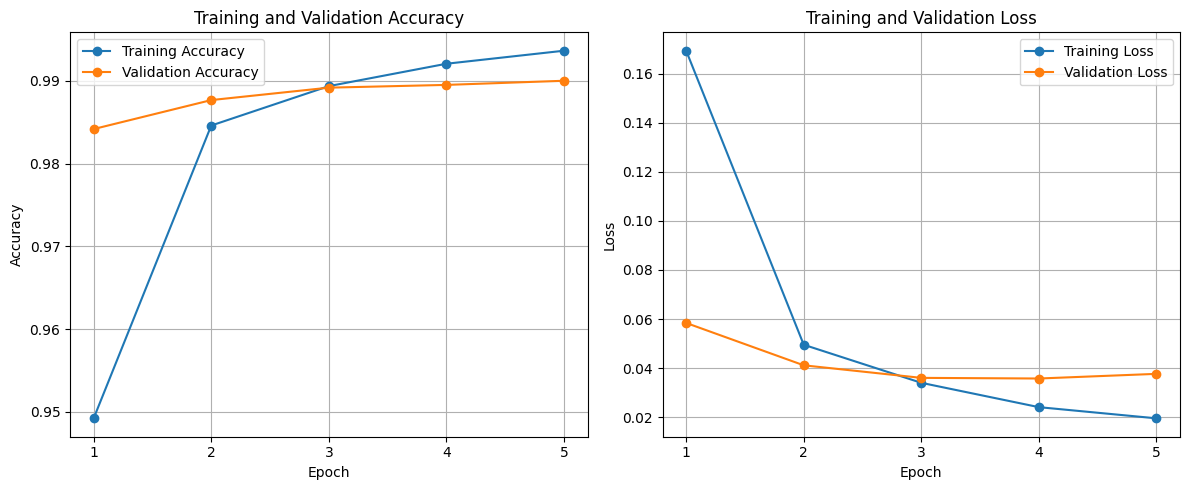


Upload an image of a handwritten digit:


Saving 0kKxxK1YXSyWMEBtS.png to 0kKxxK1YXSyWMEBtS.png


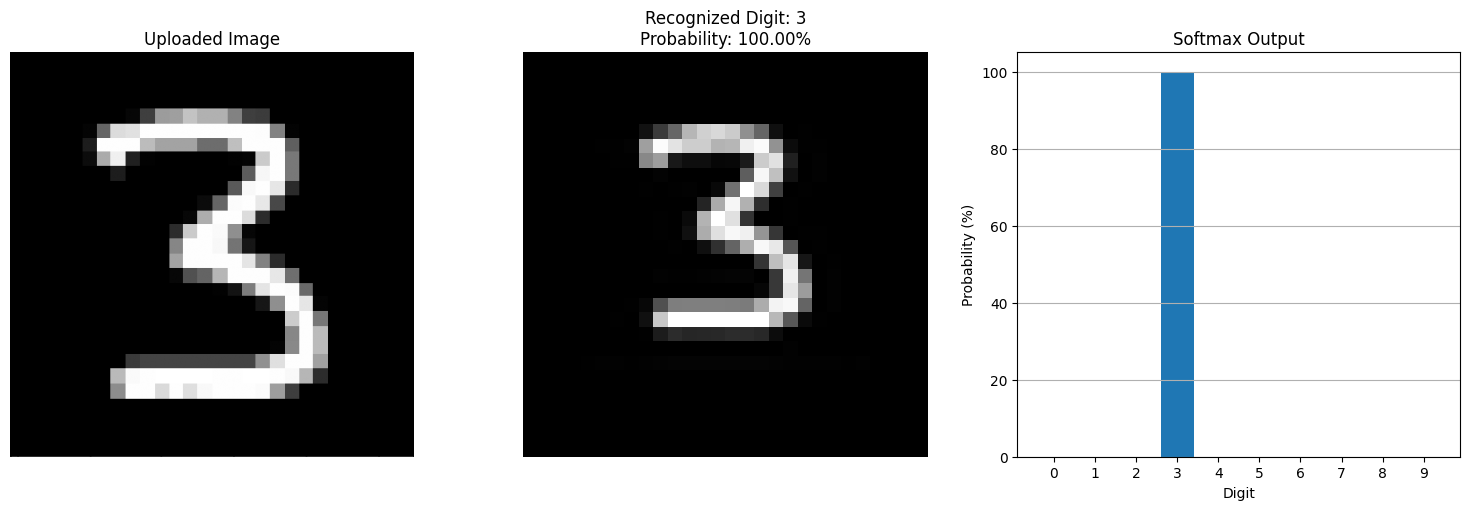


Predicted Digit: 3
Probability: 100.00%

Softmax Probabilities:
Digit 0: 0.00%
Digit 1: 0.00%
Digit 2: 0.00%
Digit 3: 100.00%
Digit 4: 0.00%
Digit 5: 0.00%
Digit 6: 0.00%
Digit 7: 0.00%
Digit 8: 0.00%
Digit 9: 0.00%


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

MODEL_FILE = "mnist_cnn.keras"
EPOCHS = 5
BATCH_SIZE = 64


def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])


# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Training data shape: {x_train.shape}")
print(f"Testing data shape : {x_test.shape}")

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# Build model
model = build_model()

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train model
history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1
)

# Evaluate model
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"\nTest Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

# Save model
model.save(MODEL_FILE)

# Plot training history
e = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    e,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    e,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(e)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    e,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    e,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(e)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


def preprocess_image(original):
    a = np.array(original)

    # Invert image if background is mostly white
    if np.mean(a) > 127:
        a = 255 - a

    # Threshold
    b = a > 50

    # Find non-empty rows and columns
    r = np.any(b, axis=1)
    c = np.any(b, axis=0)

    if np.any(r) and np.any(c):
        a = a[
            np.where(r)[0][0]:np.where(r)[0][-1] + 1,
            np.where(c)[0][0]:np.where(c)[0][-1] + 1
        ]

    # Resize while maintaining aspect ratio
    h, w = a.shape
    s = 20 / max(h, w)

    nw = max(1, int(w * s))
    nh = max(1, int(h * s))

    a = np.array(
        Image.fromarray(a.astype("uint8")).resize(
            (nw, nh),
            Image.Resampling.LANCZOS
        )
    )

    # Place digit in 28x28 canvas
    canvas = np.zeros((28, 28), dtype="uint8")

    x = (28 - nw) // 2
    y = (28 - nh) // 2

    canvas[y:y + nh, x:x + nw] = a

    return (
        canvas.astype("float32") / 255.0
    ).reshape(1, 28, 28, 1)


def predict_image(a, original):
    p = model.predict(a, verbose=0)[0]

    d = int(np.argmax(p))
    conf = p[d]

    processed = (
        a[0, :, :, 0] * 255
    ).astype("uint8")

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)

    plt.imshow(original, cmap="gray")
    plt.title("Uploaded Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)

    plt.imshow(processed, cmap="gray")
    plt.title(
        f"Recognized Digit: {d}\n"
        f"Probability: {conf * 100:.2f}%"
    )
    plt.axis("off")

    plt.subplot(1, 3, 3)

    plt.bar(range(10), p * 100)
    plt.xticks(range(10))
    plt.xlabel("Digit")
    plt.ylabel("Probability (%)")
    plt.title("Softmax Output")
    plt.grid(axis="y")

    plt.tight_layout()
    plt.show()

    print(f"\nPredicted Digit: {d}")
    print(f"Probability: {conf * 100:.2f}%")

    print("\nSoftmax Probabilities:")

    for i in range(10):
        print(f"Digit {i}: {p[i] * 100:.2f}%")


# Upload image
print("\nUpload an image of a handwritten digit:")

uploaded = files.upload()

for file_name in uploaded:
    original = Image.open(file_name).convert("L")
    image_array = preprocess_image(original)
    predict_image(image_array, original)